# Orchard surveys — analyse des vergers


# 0. Bibliothèques


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import binom, fisher_exact
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN
from scipy.stats import spearmanr
from statsmodels.tsa.seasonal import STL
from itertools import combinations
from collections import Counter

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/data_dictionary.csv').exists()), None)
assert ROOT is not None, 'Lancer le notebook depuis le dépôt.'
plt.rcParams.update({'figure.figsize':(10,4),'axes.grid':True,'grid.alpha':.2})


# 1. Charger les données


In [2]:
raw = pd.read_csv(ROOT / 'data/ecology/orchard_surveys.csv')
df = pd.read_csv(ROOT / 'data/ecology/cleaned/orchard_surveys_cleaned.csv')
print('Brut :', raw.shape, '| Nettoyé :', df.shape)


Brut : (1250, 11) | Nettoyé : (1248, 11)


In [3]:
print("Dimensions :",df.shape)
display(df.head(5))
print("Valeurs manquantes :")
display(df.isna().sum().to_frame("manquants"))
print("Doublons :",df.duplicated().sum())


Dimensions : (1248, 11)
Valeurs manquantes :
Doublons : 0


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note
0,ORC-0000001,AVL-MAR,2019-01-01,24.1,40.3,34.7,20400.8,55.2,27.1,38.4,NaN
1,ORC-0000002,AVL-MAR,2019-02-01,24.1,33.8,41.6,17712.7,63.8,44.2,41.6,NaN
2,ORC-0000003,AVL-MAR,2019-03-01,24.1,55.1,57.3,28900.5,77.4,35.2,45.6,NaN
3,ORC-0000004,AVL-MAR,2019-04-01,24.1,90.2,48.7,21992.9,67.4,22.8,36.3,NaN
4,ORC-0000005,AVL-MAR,2019-05-01,24.1,80.7,61.4,27213.5,62.9,31.9,40.7,NaN


,manquants
orchard_survey_id,0
site_code,0
survey_period,0
orchard_area_ha,0
durian_flower_density,0
fruit_set_rate_pct,0
durian_yield_kg,0
other_pollinator_activity,0
fertilizer_use_index,0
irrigation_level,0


# 2. Explorer les données et la saisonnalité


### Contrôler les relevés et les variables


In [4]:
df["survey_period"] = pd.to_datetime(df.survey_period, errors="raise")
df = df.sort_values(["site_code", "survey_period"]).reset_index(drop=True)
numeric = [
    "orchard_area_ha",
    "durian_flower_density",
    "fruit_set_rate_pct",
    "durian_yield_kg",
    "other_pollinator_activity",
    "fertilizer_use_index",
    "irrigation_level",
]
for col in numeric:
    df[col] = pd.to_numeric(df[col], errors="raise")


In [5]:
invalid = (
    df.orchard_area_ha.le(0)
    | df.durian_yield_kg.lt(0)
    | ~df.fruit_set_rate_pct.between(0, 100)
    | df[numeric].isna().any(axis=1)
)
display(df.loc[invalid])
assert not invalid.any(), "Corriger ou isoler les lignes invalides avant calcul."
assert not df.duplicated(["site_code", "survey_period"]).any()
df["yield_kg_ha"] = df.durian_yield_kg / df.orchard_area_ha
df["month"] = df.survey_period.dt.month
df["year"] = df.survey_period.dt.year


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note


In [6]:
coverage = df.groupby("site_code").agg(
    n=("survey_period", "size"),
    debut=("survey_period", "min"),
    fin=("survey_period", "max"),
    superficies_distinctes=("orchard_area_ha", "nunique"),
)
display(coverage)
ordinal = df.survey_period.dt.year * 12 + df.survey_period.dt.month
gap = ordinal.groupby(df.site_code).diff()
assert gap.dropna().eq(1).all(), "Mois manquants : adapter les différences et lag 12."
display(df[["yield_kg_ha", "fruit_set_rate_pct"]].describe())


,n,debut,fin,superficies_distinctes
site_code,,,,
AVL-ECJ,78,2019-01-01,2025-06-01,1
AVL-FNQ,78,2019-01-01,2025-06-01,1
AVL-GRB,78,2019-01-01,2025-06-01,1
AVL-HUA,78,2019-01-01,2025-06-01,1
AVL-KAR,78,2019-01-01,2025-06-01,1
AVL-MAR,78,2019-01-01,2025-06-01,1
AVL-NFR,78,2019-01-01,2025-06-01,1
AVL-NMQ,78,2019-01-01,2025-06-01,1
AVL-ORR,78,2019-01-01,2025-06-01,1


,yield_kg_ha,fruit_set_rate_pct
count,1248.000000,1248.000000
mean,1041.185472,53.550080
std,197.394017,9.307769
min,392.783088,27.300000
25%,905.848398,47.000000
50%,1038.250542,53.000000
75%,1164.736389,59.400000
max,1815.731518,87.700000


### Visualiser rendements et saisons


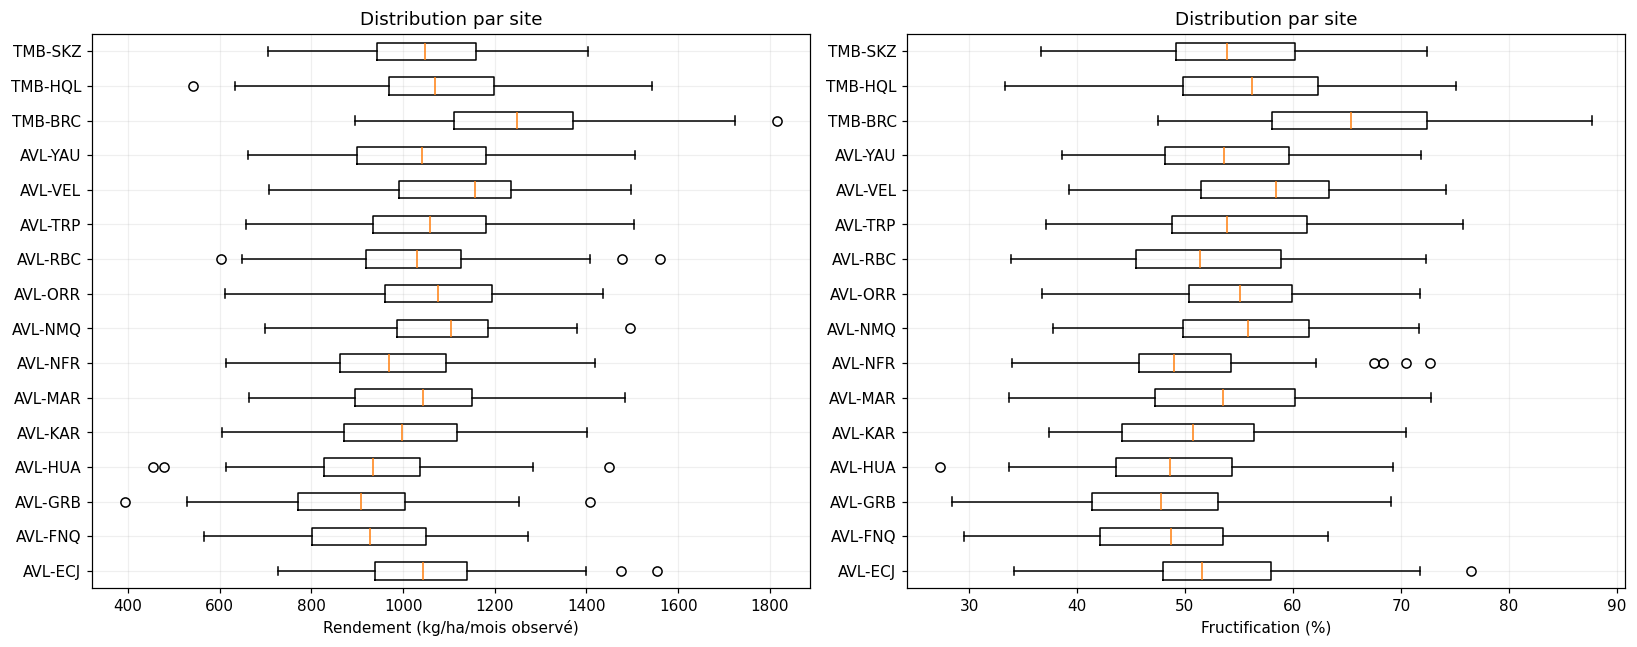

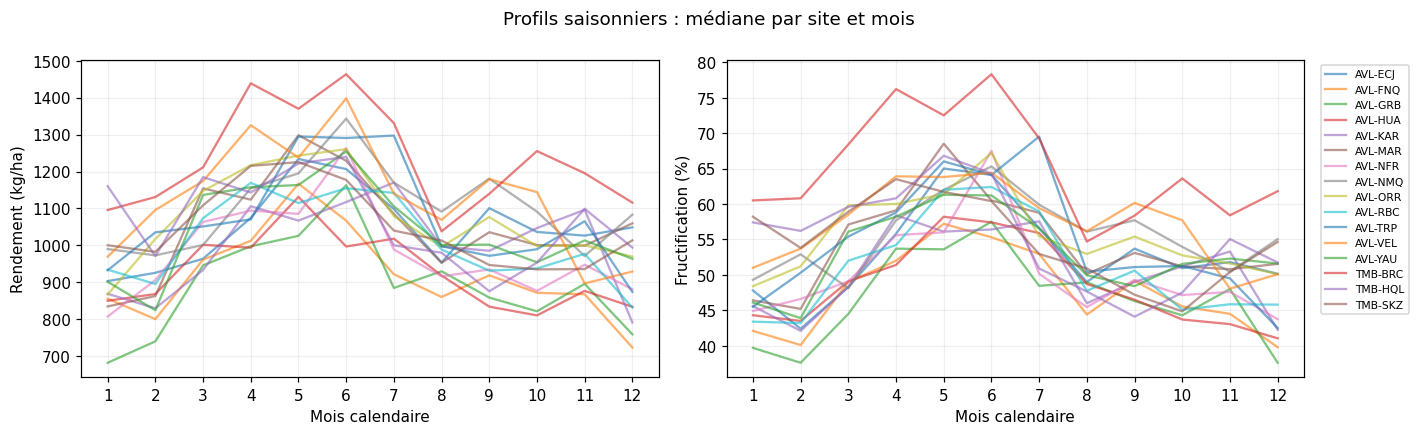

In [7]:
sites = sorted(df.site_code.unique())
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, var, label in zip(
    axes,
    ["yield_kg_ha", "fruit_set_rate_pct"],
    ["Rendement (kg/ha/mois observé)", "Fructification (%)"],
):
    ax.boxplot(
        [df.loc[df.site_code.eq(s), var] for s in sites], vert=False, tick_labels=sites
    )
    ax.set_xlabel(label)
    ax.set_title("Distribution par site")
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for site, g in df.groupby("site_code"):
    for ax, var in zip(axes, ["yield_kg_ha", "fruit_set_rate_pct"]):
        med = g.groupby("month")[var].median()
        ax.plot(med.index, med.values, alpha=0.6, label=site)
for ax, label in zip(axes, ["Rendement (kg/ha)", "Fructification (%)"]):
    ax.set_xlabel("Mois calendaire")
    ax.set_ylabel(label)
    ax.set_xticks(range(1, 13))
axes[1].legend(bbox_to_anchor=(1.02, 1), fontsize=7)
fig.suptitle("Profils saisonniers : médiane par site et mois")
fig.tight_layout()
plt.show()


In [8]:
display(
    Markdown(
        "**Lecture :** les différences entre sites et entre mois motivent une référence locale saisonnière. Les variations brutes ne suffisent pas à conclure à une rupture."
    )
)


**Lecture :** les différences entre sites et entre mois motivent une référence locale saisonnière. Les variations brutes ne suffisent pas à conclure à une rupture.

### Comparer les années à mois identiques


In [9]:
first_half = (
    df.loc[df.month.le(6)]
    .groupby(["site_code", "year"])
    .agg(
        yield_mean=("yield_kg_ha", "mean"),
        fruit_mean=("fruit_set_rate_pct", "mean"),
        n=("orchard_survey_id", "size"),
    )
)
assert first_half.n.eq(6).all(), "Semestres incomplets : ne pas comparer directement."
display(first_half.yield_mean.unstack().round(1))
display(first_half.fruit_mean.unstack().round(1))
recent = first_half.xs(2025, level="year").join(
    first_half.xs(2024, level="year"), lsuffix="_2025", rsuffix="_2024"
)


year,2019,2020,2021,2022,2023,2024,2025
site_code,,,,,,,
AVL-ECJ,1114.8,1025.0,1041.1,1011.0,1047.0,1178.7,1059.6
AVL-FNQ,1045.4,1014.6,856.5,890.1,1010.2,980.1,983.6
AVL-GRB,891.1,898.7,954.6,960.4,914.4,903.6,952.9
AVL-HUA,950.6,1003.1,1030.3,898.6,991.5,935.8,966.9
AVL-KAR,1011.9,1062.1,1012.8,999.2,988.9,1005.5,976.8
AVL-MAR,1026.0,1060.7,1025.7,1023.4,1063.4,1111.3,1128.4
AVL-NFR,1039.8,905.2,1020.3,965.1,1000.6,1165.9,1043.7
AVL-NMQ,1128.2,1022.9,1035.6,1173.4,1149.7,1096.0,1107.2
AVL-ORR,1055.9,1141.8,1140.6,1188.5,1168.0,1087.5,1077.4


year,2019,2020,2021,2022,2023,2024,2025
site_code,,,,,,,
AVL-ECJ,57.2,53.0,52.1,52.3,53.1,58.2,54.4
AVL-FNQ,52.7,51.1,45.6,49.7,51.1,49.0,50.0
AVL-GRB,46.4,46.7,49.6,51.4,44.4,47.9,49.2
AVL-HUA,50.6,51.1,52.4,48.1,50.7,49.8,50.2
AVL-KAR,51.8,53.4,51.5,51.5,50.1,52.1,48.7
AVL-MAR,50.7,55.5,54.9,54.6,55.8,57.8,56.8
AVL-NFR,51.0,48.8,54.4,52.8,50.6,56.2,53.6
AVL-NMQ,58.4,54.4,53.7,59.8,57.8,55.9,54.4
AVL-ORR,54.3,57.6,56.2,60.0,59.0,53.8,57.5


In [10]:
recent["yield_change_pct"] = (recent.yield_mean_2025 / recent.yield_mean_2024 - 1) * 100
recent["fruit_change_pp"] = recent.fruit_mean_2025 - recent.fruit_mean_2024
display(
    recent[["yield_change_pct", "fruit_change_pp"]]
    .sort_values("yield_change_pct")
    .round(2)
)
display(
    Markdown(
        "**Lecture :** les tableaux distinguent un niveau propre au site, une variation d’une année à l’autre et un incident mensuel. Une baisse ponctuelle ne démontre pas un déclin durable."
    )
)


,yield_change_pct,fruit_change_pp
site_code,,
AVL-NFR,-10.48,-2.58
AVL-ECJ,-10.10,-3.78
AVL-RBC,-5.56,-2.42
AVL-KAR,-2.86,-3.38
TMB-SKZ,-2.68,-3.53
AVL-ORR,-0.92,3.68
TMB-BRC,-0.39,0.23
TMB-HQL,0.22,0.77
AVL-FNQ,0.36,1.02


**Lecture :** les tableaux distinguent un niveau propre au site, une variation d’une année à l’autre et un incident mensuel. Une baisse ponctuelle ne démontre pas un déclin durable.

### Corrélations de Pearson et Spearman


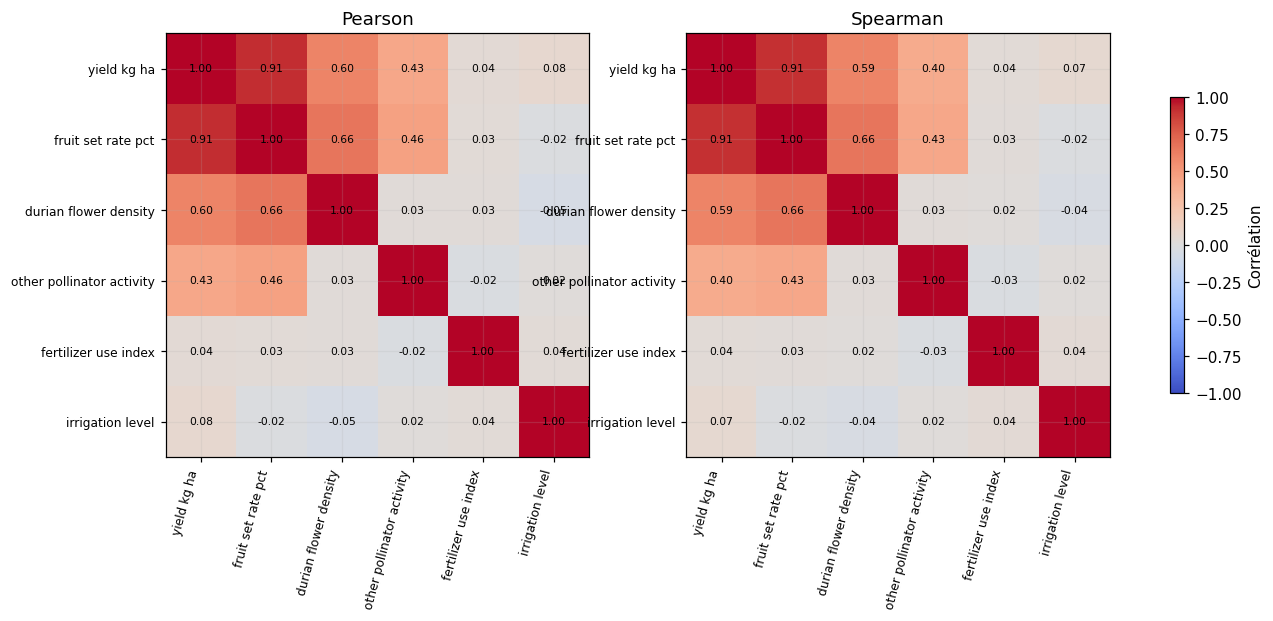

In [11]:
mesures = ["yield_kg_ha", "fruit_set_rate_pct", "durian_flower_density",
           "other_pollinator_activity", "fertilizer_use_index", "irrigation_level"]
correlations = {m: df[mesures].corr(method=m) for m in ["pearson", "spearman"]}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (methode, matrice) in zip(axes, correlations.items()):
    im = ax.imshow(matrice, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(mesures)), [x.replace("_", " ") for x in mesures],
                  rotation=75, ha="right", fontsize=8)
    ax.set_yticks(range(len(mesures)), [x.replace("_", " ") for x in mesures], fontsize=8)
    ax.set_title(methode.capitalize())
    for ligne in range(len(mesures)):
        for colonne in range(len(mesures)):
            ax.text(colonne, ligne, f"{matrice.iloc[ligne, colonne]:.2f}",
                    ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=axes, shrink=.7, label="Corrélation")
plt.show()


In [12]:
display(pd.DataFrame({m: mat["yield_kg_ha"] for m, mat in correlations.items()})
        .drop(index="yield_kg_ha").round(3))


,pearson,spearman
fruit_set_rate_pct,0.915,0.908
durian_flower_density,0.597,0.595
other_pollinator_activity,0.427,0.401
fertilizer_use_index,0.042,0.036
irrigation_level,0.076,0.066


**Lecture :** Pearson mesure les relations linéaires ; Spearman compare les rangs. Ici, les corrélations mélangent les sites et les saisons : elles restent descriptives et ne prouvent pas une cause.


### Nuages de points entre les variables


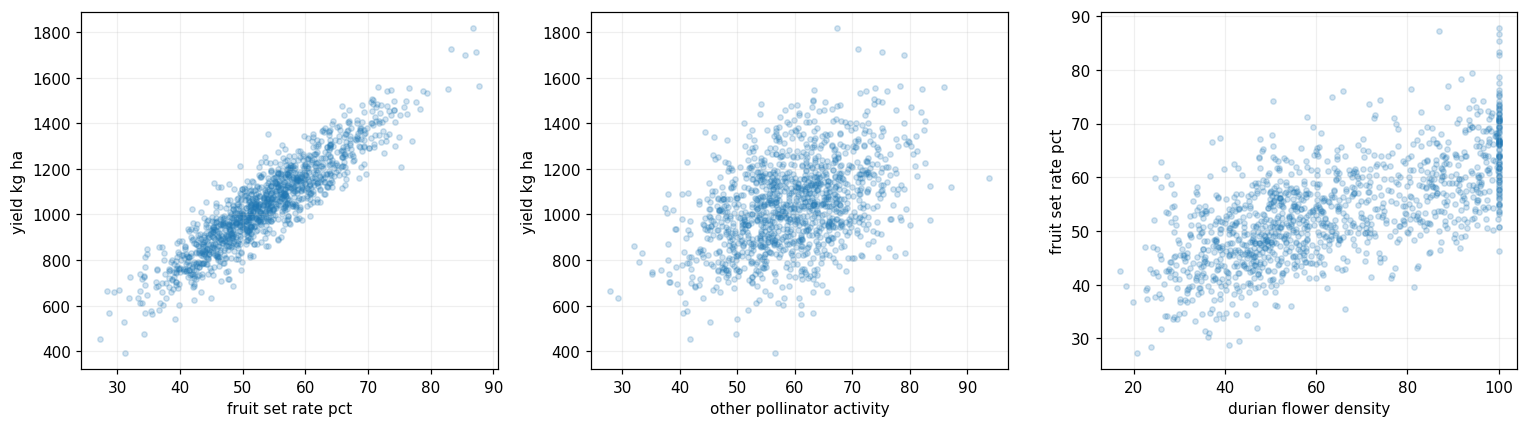

In [13]:
couples = [("fruit_set_rate_pct", "yield_kg_ha"),
           ("other_pollinator_activity", "yield_kg_ha"),
           ("durian_flower_density", "fruit_set_rate_pct")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (x, y) in zip(axes, couples):
    ax.scatter(df[x], df[y], alpha=.2, s=12)
    ax.set(xlabel=x.replace("_", " "), ylabel=y.replace("_", " "))
plt.tight_layout(); plt.show()


**Lecture :** ces graphiques aident à voir les relations et les valeurs extrêmes. Les variations entre vergers et entre mois peuvent expliquer une partie des formes observées.


### Calculer les résidus saisonniers


In [14]:
features = [
    "yield_kg_ha",
    "fruit_set_rate_pct",
    "durian_flower_density",
    "other_pollinator_activity",
    "fertilizer_use_index",
    "irrigation_level",
]


In [15]:
for var in features:
    baseline = pd.Series(np.nan, index=df.index)
    for _, g in df.groupby(["site_code", "month"]):
        for idx in g.index:
            other = g.loc[g.index != idx, var].dropna()
            if len(other) >= 4:
                baseline.at[idx] = other.median()
    df[var + "_expected"] = baseline
    df[var + "_resid"] = df[var] - baseline
for var in ["yield_kg_ha", "fruit_set_rate_pct"]:
    df[var + "_delta_resid"] = df.groupby("site_code")[var + "_resid"].diff()
prev_yield = df.groupby("site_code").yield_kg_ha.shift(12)
df["yield_yoy_pct"] = (df.yield_kg_ha / prev_yield - 1) * 100


In [16]:
df["fruit_yoy_pp"] = df.fruit_set_rate_pct - df.groupby(
    "site_code"
).fruit_set_rate_pct.shift(12)
assert df[[v + "_resid" for v in features]].notna().all().all()


In [17]:
display(
    df.nsmallest(10, "yield_yoy_pct")[
        [
            "orchard_survey_id",
            "site_code",
            "survey_period",
            "yield_kg_ha",
            "yield_yoy_pct",
            "fruit_yoy_pp",
            "agricultural_disturbance_note",
        ]
    ]
)


,orchard_survey_id,site_code,survey_period,yield_kg_ha,yield_yoy_pct,fruit_yoy_pp,agricultural_disturbance_note
265,ORC-0000812,AVL-HUA,2021-08-01,477.991614,-54.546234,-22.8,NaN
1136,ORC-0001215,TMB-HQL,2022-09-01,542.592760,-49.390344,-17.1,NaN
685,ORC-0000218,AVL-ORR,2024-02-01,611.862647,-46.131623,-17.2,NaN
1111,ORC-0001190,TMB-HQL,2020-08-01,633.255656,-45.856425,-29.1,NaN
271,ORC-0000818,AVL-HUA,2022-02-01,454.270440,-45.067712,-7.5,NaN
517,ORC-0000362,AVL-NFR,2023-02-01,613.905738,-43.542302,-16.3,NaN
826,ORC-0000281,AVL-TRP,2022-11-01,727.385740,-40.255119,-21.5,NaN
133,ORC-0000992,AVL-FNQ,2023-08-01,658.607330,-39.440593,-22.6,NaN
558,ORC-0000871,AVL-NMQ,2020-01-01,698.092652,-39.042095,-13.7,NaN
189,ORC-0000424,AVL-GRB,2021-10-01,705.025735,-38.326786,-21.8,NaN


# 3. Bloc 2 — Clustering et réduction de dimension


### a. ACP sur les profils des vergers


In [18]:
site_profiles = df.groupby("site_code").agg(
    rendement_moyen=("yield_kg_ha", "mean"),
    rendement_ecart_type=("yield_kg_ha", "std"),
    fructification_moyenne=("fruit_set_rate_pct", "mean"),
    fructification_ecart_type=("fruit_set_rate_pct", "std"),
    pollinisateurs_moyen=("other_pollinator_activity", "mean"),
    fertilisant_moyen=("fertilizer_use_index", "mean"),
)
assert site_profiles.notna().all().all() and len(site_profiles) == 16
scaler_sites = StandardScaler()
X_sites = scaler_sites.fit_transform(site_profiles)


In [19]:
pca_sites = PCA(n_components=2)
coords_sites = pca_sites.fit_transform(X_sites)
silhouettes = []
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_sites)
    silhouettes.append(
        {
            "k": k,
            "silhouette": silhouette_score(X_sites, km.labels_),
            "taille_min_groupe": int(np.bincount(km.labels_).min()),
        }
    )
score_sites = pd.DataFrame(silhouettes)


### b. K-Means : choix de k


In [20]:
valid_scores = score_sites.loc[score_sites.taille_min_groupe >= 2]
assert not valid_scores.empty
best_k = int(
    valid_scores.sort_values(["silhouette", "k"], ascending=[False, True]).iloc[0]["k"]
)
model_sites = KMeans(n_clusters=best_k, n_init=20, random_state=42).fit(X_sites)
site_profiles["cluster_exploratoire"] = model_sites.labels_
print(
    "Variance représentée par les deux premières composantes :",
    [round(v, 3) for v in pca_sites.explained_variance_ratio_],
)
display(score_sites)


Variance représentée par les deux premières composantes : [np.float64(0.606), np.float64(0.189)]


,k,silhouette,taille_min_groupe
0,2,0.294196,8
1,3,0.280734,1
2,4,0.369086,1


In [21]:
print(
    "Choix k =",
    best_k,
    "(meilleure silhouette parmi les partitions sans groupe singleton).",
)
display(
    site_profiles.groupby("cluster_exploratoire")
    .agg(
        n_sites=("rendement_moyen", "size"),
        rendement_moyen=("rendement_moyen", "mean"),
        fructification_moyenne=("fructification_moyenne", "mean"),
        pollinisateurs_moyen=("pollinisateurs_moyen", "mean"),
    )
    .round(2)
)


Choix k = 2 (meilleure silhouette parmi les partitions sans groupe singleton).


,n_sites,rendement_moyen,fructification_moyenne,pollinisateurs_moyen
cluster_exploratoire,,,,
0,8,1087.47,55.93,62.21
1,8,994.90,51.17,56.68


**Interprétation des groupes :** K-Means sépare les 16 vergers en deux groupes de 8. Le cluster 0 a en moyenne un **rendement plus élevé** (1 087 contre 995 kg/ha), une **fructification plus forte** (55,93 % contre 51,17 %) et un peu plus d’activité des autres pollinisateurs (62,21 contre 56,68). Ces différences décrivent les profils moyens des vergers : elles ne suffisent pas à expliquer les baisses ponctuelles de rendement.


In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    coords_sites[:, 0], coords_sites[:, 1], c=model_sites.labels_, cmap="tab10", s=65
)


### c. Visualisation ACP et comparaison CAH


Lecture : ces classes résument des profils de sites ; elles ne remplacent pas les anomalies mensuelles et ne prouvent aucune causalité.


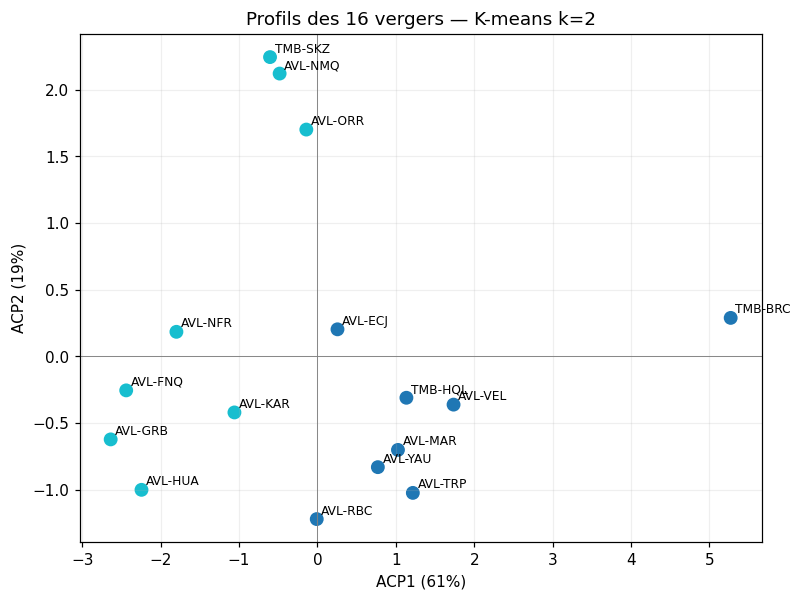

In [23]:
for (x, y), code_site in zip(coords_sites, site_profiles.index):
    ax.annotate(
        code_site, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=8
    )
ax.set(
    xlabel=f"ACP1 ({pca_sites.explained_variance_ratio_[0]:.0%})",
    ylabel=f"ACP2 ({pca_sites.explained_variance_ratio_[1]:.0%})",
    title=f"Profils des 16 vergers — K-means k={best_k}",
)
ax.axhline(0, color="gray", lw=0.6)
ax.axvline(0, color="gray", lw=0.6)
plt.show()
print(
    "Lecture : ces classes résument des profils de sites ; elles ne remplacent pas les anomalies mensuelles et ne prouvent aucune causalité."
)


In [24]:
hierarchical_sites = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
hierarchical_labels = hierarchical_sites.fit_predict(X_sites)
agreement_ari = adjusted_rand_score(model_sites.labels_, hierarchical_labels)
print(f"Accord K-means / CAH (ARI ajusté) : {agreement_ari:.3f}")
print("L’ARI vaut 1 pour des partitions identiques ; un faible accord invite à la prudence sur les profils retenus.")


Accord K-means / CAH (ARI ajusté) : 0.749
L’ARI vaut 1 pour des partitions identiques ; un faible accord invite à la prudence sur les profils retenus.


### CAH : dendrogramme des 16 vergers


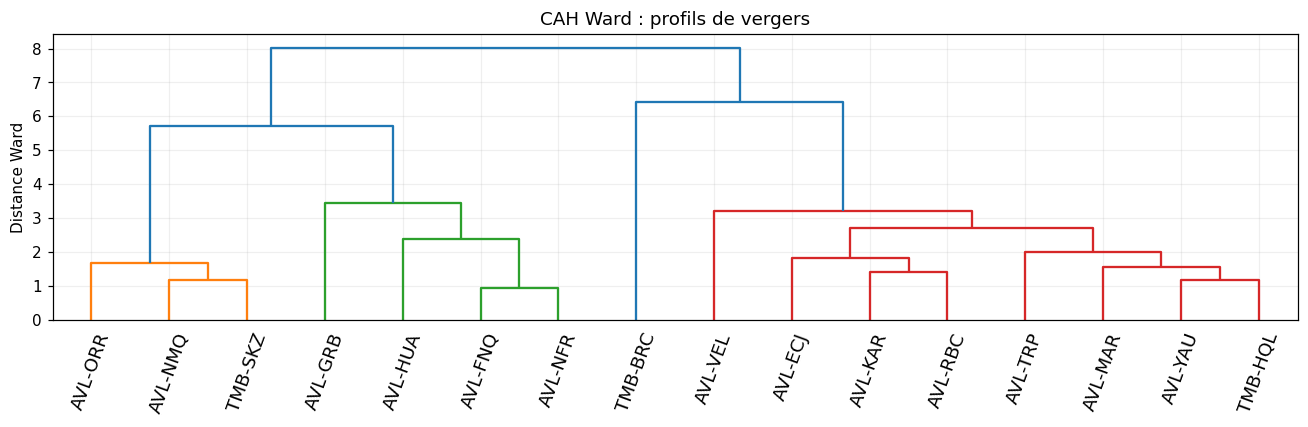

In [25]:
hierarchie_vergers=linkage(X_sites,method='ward')
fig,ax=plt.subplots(figsize=(12,4))
dendrogram(hierarchie_vergers,labels=site_profiles.index.tolist(),
           leaf_rotation=70,ax=ax)
ax.set(title='CAH Ward : profils de vergers',ylabel='Distance Ward')
plt.tight_layout();plt.show()

### Autres projections (cours 2)


### d. t-SNE : comparaison avec l’ACP


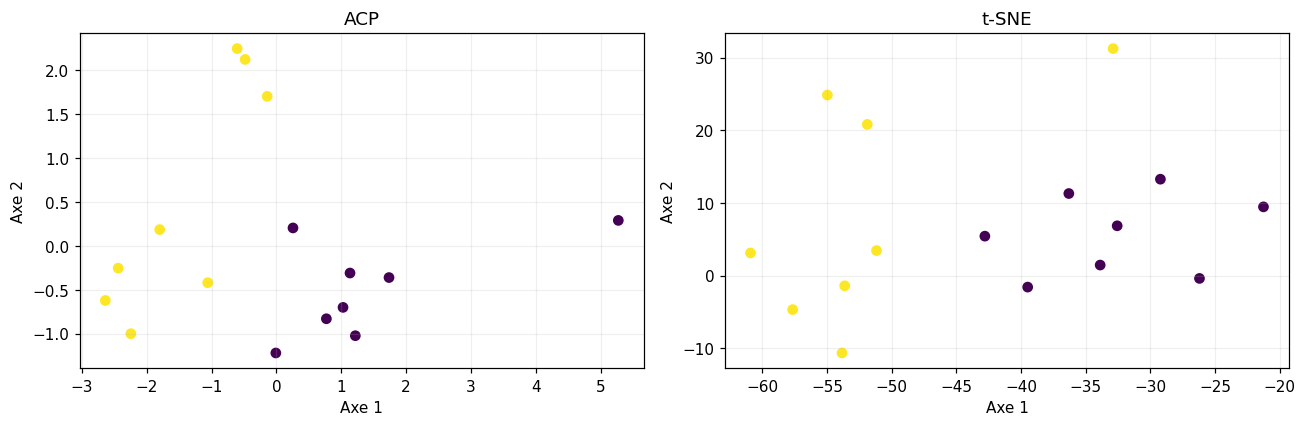

In [26]:
projection_tsne = TSNE(n_components=2,perplexity=5,init='random',
                       learning_rate='auto',random_state=42).fit_transform(X_sites)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,points,nom in zip(axes,[coords_sites,projection_tsne],['ACP','t-SNE']):
    ax.scatter(points[:,0],points[:,1],c=site_profiles.cluster_exploratoire)
    ax.set(title=nom,xlabel='Axe 1',ylabel='Axe 2')
plt.tight_layout();plt.show()

**Lecture :** t-SNE illustre les voisinages, mais la projection est fragile avec 16 sites.


### e. DBSCAN sur les profils des vergers


In [27]:
db_vergers=[]
for eps in [1.5,2.0,2.5]:
    labels=DBSCAN(eps=eps,min_samples=3).fit_predict(X_sites)
    db_vergers.append({'eps':eps,'groupes':len(set(labels)-{-1}),
                       'sites_bruit':int((labels==-1).sum())})
display(pd.DataFrame(db_vergers))

,eps,groupes,sites_bruit
0,1.5,2,5
1,2.0,2,3
2,2.5,1,1


**Lecture :** la classification dépend fortement du rayon ; aucun site n’est automatiquement incorrect.


# 4. Bloc 3 — Détection d’anomalies


**Pourquoi garder les valeurs atypiques ?** Une baisse de rendement ou de fructification peut venir d’un événement agricole, d’un changement de saison ou d’un problème de mesure. Les tests servent ici à repérer les relevés à revoir, **pas à supprimer automatiquement les valeurs extrêmes**. On les conserve donc pour pouvoir les comparer aux notes de perturbation et aux autres données écologiques.


### a. IQR, Z-score et MAD


#### Calculer les seuils


In [28]:
def seuils_pour_variable(x, min_n=8, haut_seul=False):
    valeurs = x.dropna()
    n = len(valeurs)
    q1, q3 = valeurs.quantile([.25, .75]) if n else (np.nan, np.nan)
    moyenne, ecart_type = valeurs.mean(), valeurs.std(ddof=1)
    mediane = valeurs.median()
    mad = (valeurs - mediane).abs().median()
    bornes = [
        ('IQR', q1-1.5*(q3-q1), q3+1.5*(q3-q1), x, q3-q1, 'hors Q1−1.5×IQR ; Q3+1.5×IQR'),
        ('Z-score', moyenne-3*ecart_type, moyenne+3*ecart_type,
         (x-moyenne)/ecart_type if ecart_type>0 else x*0+np.nan, ecart_type, '|z| > 3'),
        ('Z-modifie', mediane-3.5*mad/.6745, mediane+3.5*mad/.6745,
         .6745*(x-mediane)/mad if mad>0 else x*0+np.nan, mad, '|z_mod| > 3.5')]
    return n, bornes


#### Repérer les valeurs atypiques


In [29]:
def lignes_signalees(g, cle, variable, groupe, min_n=8, haut_seul=False):
    x = pd.to_numeric(g[variable], errors='raise').replace([np.inf, -np.inf], np.nan)
    n, bornes = seuils_pour_variable(x, min_n, haut_seul)
    observations = []
    for methode, bas, haut, scores, ecart, regle in bornes:
        utilisable = n >= min_n and pd.notna(ecart) and ecart > 1e-12
        if haut_seul:
            bas = -np.inf
            regle += ' (queue haute uniquement)'
        for idx in g.index:
            valeur = x.loc[idx]
            applicable = bool(utilisable and pd.notna(valeur))
            observations.append(dict(
                observation=str(g.at[idx, cle]), groupe=groupe, variable=variable,
                methode=methode, valeur=valeur,
                score=scores.loc[idx] if applicable else np.nan,
                borne_basse=bas if utilisable else np.nan,
                borne_haute=haut if utilisable else np.nan, n_reference=n,
                applicable=applicable,
                signalee=bool(applicable and (valeur < bas or valeur > haut)),
                regle=regle if utilisable else f'Non évalué : n < {min_n} ou dispersion nulle',
                interpretation='Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.'))
    return observations


#### Comparer les observations par site


In [30]:
def statistiques(data, cle, variables, groupes=(), min_n=8, haut_seul=False):
    """IQR, Z et MAD par groupe comparable ; pas d'imputation."""
    tous = []
    parts = (data.groupby(list(groupes), dropna=False, sort=True)
             if groupes else [('ensemble', data)])
    for identifiant, part in parts:
        if groupes:
            valeurs = identifiant if isinstance(identifiant, tuple) else (identifiant,)
            etiquette = '; '.join(f'{col}={val}' for col, val in zip(groupes, valeurs))
        else:
            etiquette = 'ensemble'
        for variable in variables:
            tous.extend(lignes_signalees(part, cle, variable, etiquette, min_n, haut_seul))
    return pd.DataFrame(tous)


#### Résumé des détections


In [31]:
def resume_tests(tests):
    display(
        tests.groupby(["variable", "methode"])
        .agg(evaluations=("applicable", "sum"), signalees=("signalee", "sum"))
        .reset_index()
    )
    skipped = tests.loc[
        ~tests.applicable, ["groupe", "variable", "methode", "regle"]
    ].drop_duplicates()
    if len(skipped):
        print("Cas non évalués (extrait) :")
        display(skipped.head(12))


In [32]:
variables = [
    "yield_kg_ha_resid",
    "fruit_set_rate_pct_resid",
    "yield_kg_ha_delta_resid",
    "fruit_set_rate_pct_delta_resid",
]
tests = statistiques(df, "orchard_survey_id", variables, ["site_code"])
resume_tests(tests)
df["stat_flag"] = df.orchard_survey_id.isin(tests.loc[tests.signalee, "observation"])
stats_summary = df.groupby("site_code").agg(
    releves=("orchard_survey_id", "size"), signales=("stat_flag", "sum")
)
display(stats_summary)


Cas non évalués (extrait) :


,variable,methode,evaluations,signalees
0,fruit_set_rate_pct_delta_resid,IQR,1232,5
1,fruit_set_rate_pct_delta_resid,Z-modifie,1232,0
2,fruit_set_rate_pct_delta_resid,Z-score,1232,0
3,fruit_set_rate_pct_resid,IQR,1248,9
4,fruit_set_rate_pct_resid,Z-modifie,1248,0
5,fruit_set_rate_pct_resid,Z-score,1248,1
6,yield_kg_ha_delta_resid,IQR,1232,18
7,yield_kg_ha_delta_resid,Z-modifie,1232,6
8,yield_kg_ha_delta_resid,Z-score,1232,2
9,yield_kg_ha_resid,IQR,1248,14


,groupe,variable,methode,regle
468,site_code=AVL-ECJ,yield_kg_ha_delta_resid,IQR,hors Q1−1.5×IQR ; Q3+1.5×IQR
546,site_code=AVL-ECJ,yield_kg_ha_delta_resid,Z-score,|z| > 3
624,site_code=AVL-ECJ,yield_kg_ha_delta_resid,Z-modifie,|z_mod| > 3.5
702,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,IQR,hors Q1−1.5×IQR ; Q3+1.5×IQR
780,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,Z-score,|z| > 3
858,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,Z-modifie,|z_mod| > 3.5
1404,site_code=AVL-FNQ,yield_kg_ha_delta_resid,IQR,hors Q1−1.5×IQR ; Q3+1.5×IQR
1482,site_code=AVL-FNQ,yield_kg_ha_delta_resid,Z-score,|z| > 3
1560,site_code=AVL-FNQ,yield_kg_ha_delta_resid,Z-modifie,|z_mod| > 3.5
1638,site_code=AVL-FNQ,fruit_set_rate_pct_delta_resid,IQR,hors Q1−1.5×IQR ; Q3+1.5×IQR


,releves,signales
site_code,,
AVL-ECJ,78,4
AVL-FNQ,78,3
AVL-GRB,78,1
AVL-HUA,78,7
AVL-KAR,78,0
AVL-MAR,78,1
AVL-NFR,78,5
AVL-NMQ,78,0
AVL-ORR,78,0


In [33]:
display(
    Markdown(
        f"**Lecture calculée :** {int(df.stat_flag.sum())} relevés présentent au moins un signal parmi "
        "les trois méthodes et les quatre variables contextuelles. Les tests sont corrélés : le nombre de détections n'est pas un nombre de preuves indépendantes."
    )
)


**Lecture calculée :** 35 relevés présentent au moins un signal parmi les trois méthodes et les quatre variables contextuelles. Les tests sont corrélés : le nombre de détections n'est pas un nombre de preuves indépendantes.

### Visualiser les anomalies dans le temps


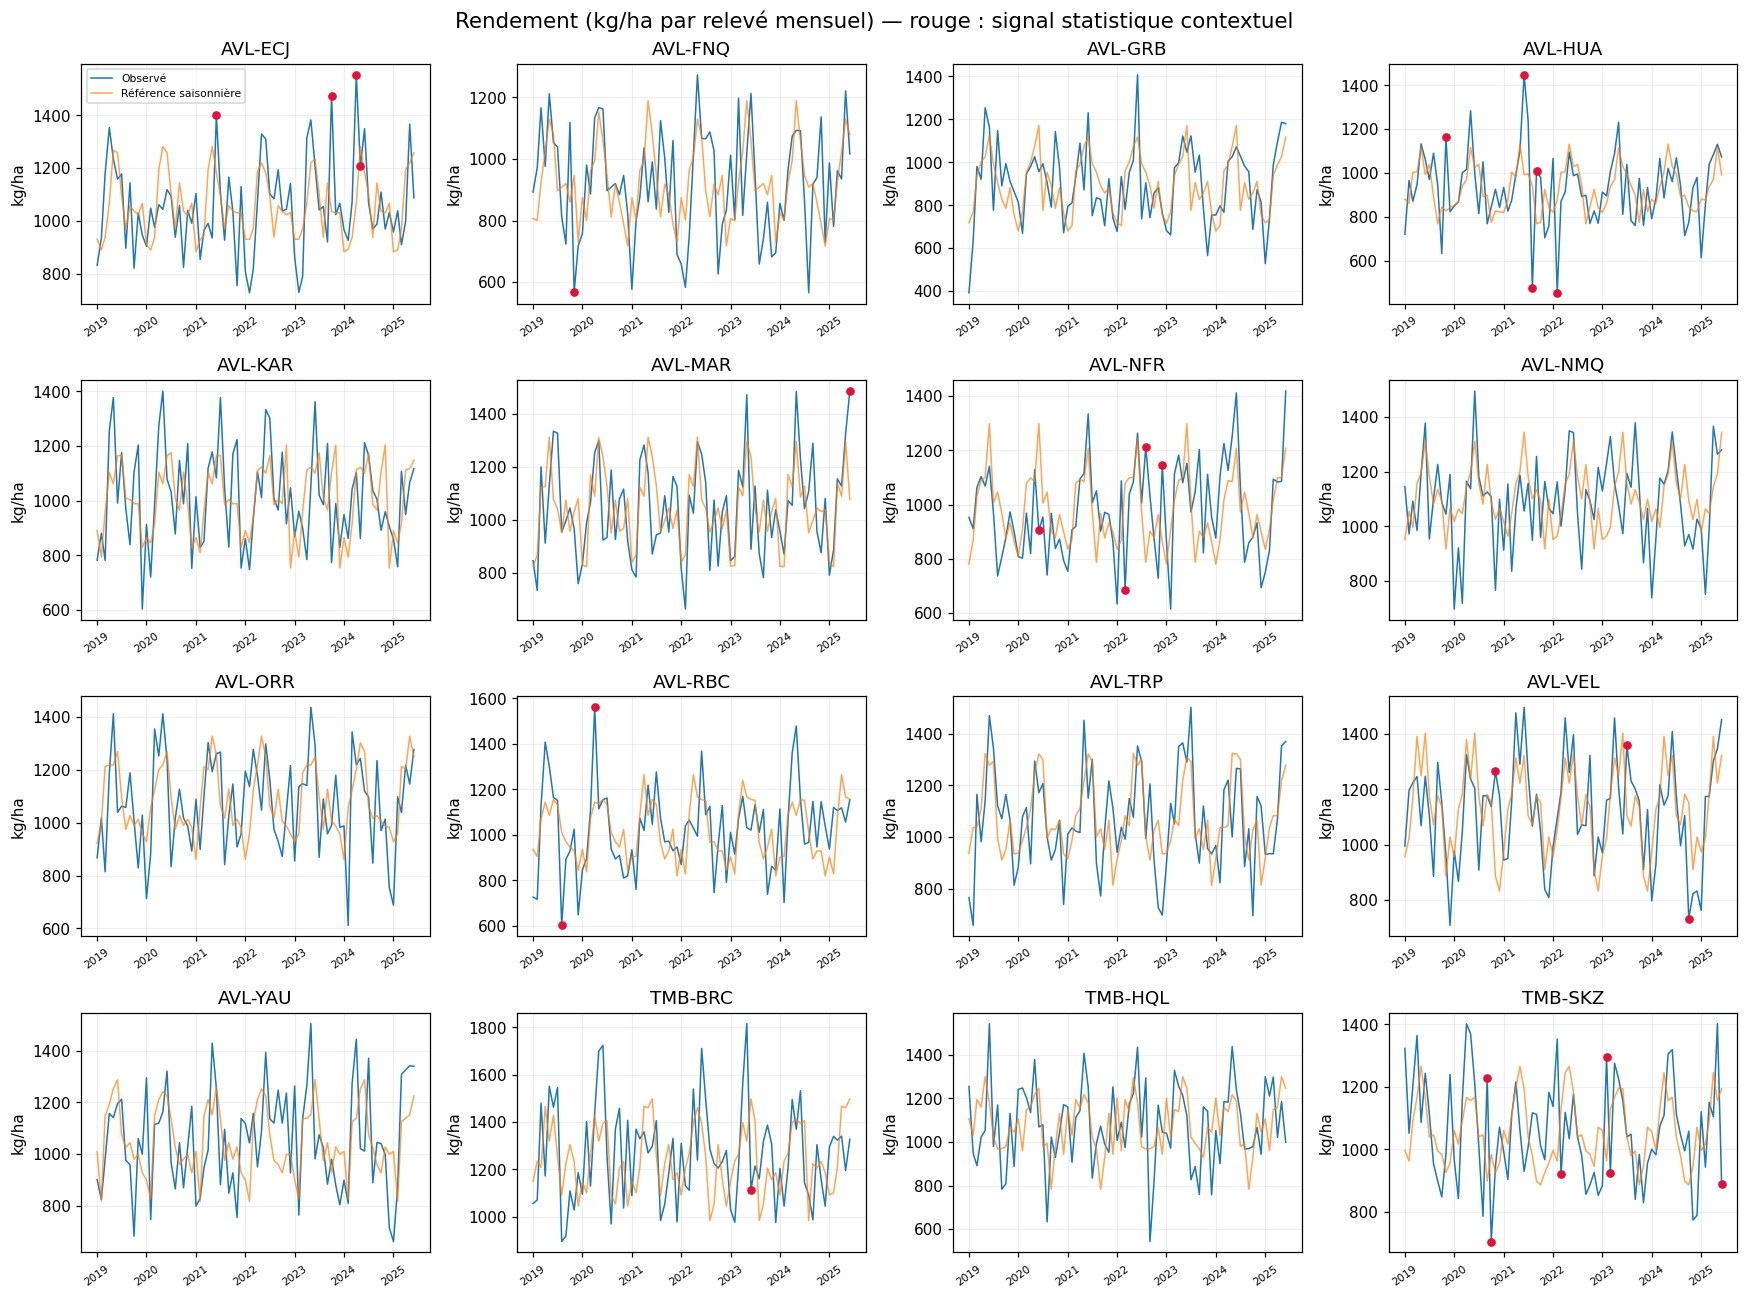

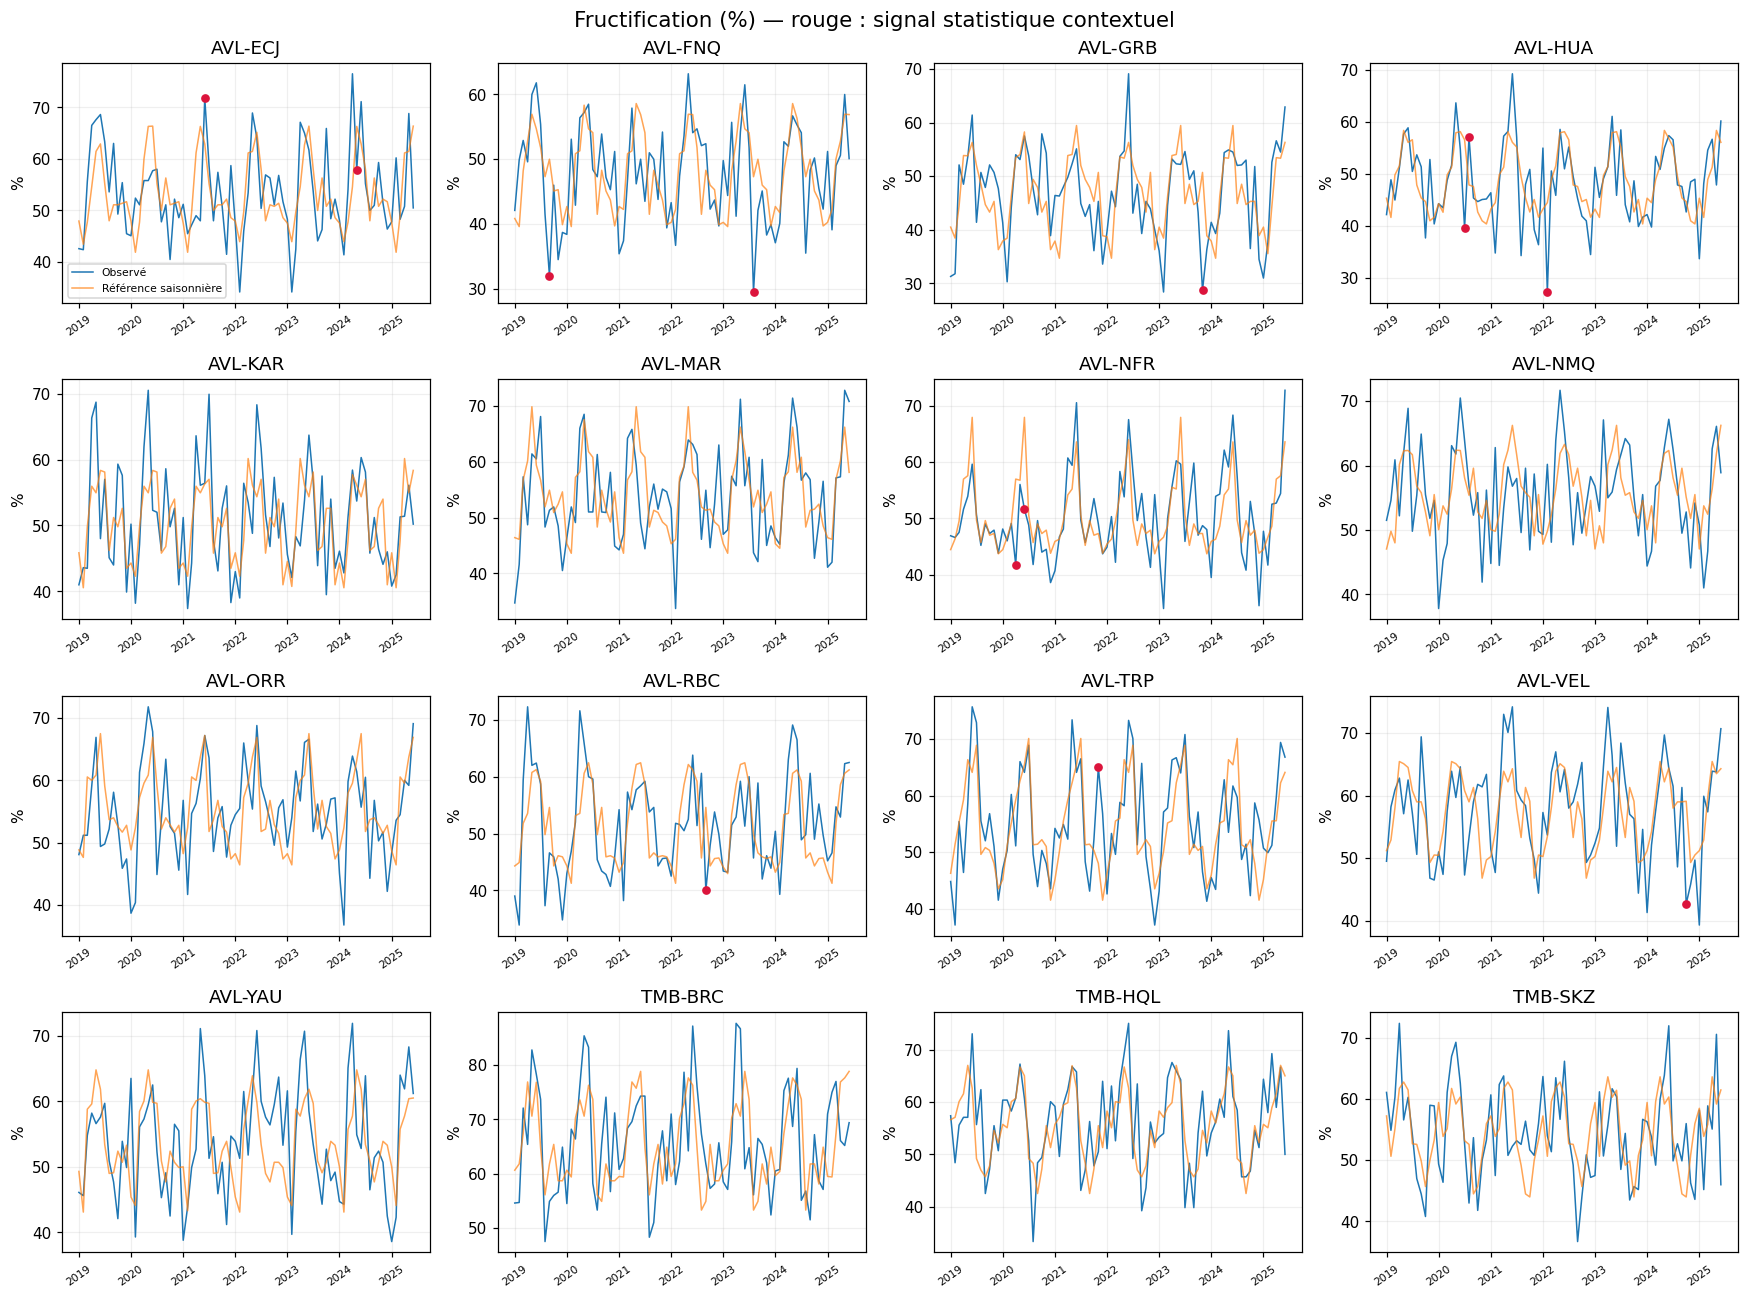

In [34]:
for var, label in [
    ("yield_kg_ha", "Rendement (kg/ha par relevé mensuel)"),
    ("fruit_set_rate_pct", "Fructification (%)"),
]:
    marked = tests.loc[
        tests.signalee & tests.variable.str.startswith(var), "observation"
    ]
    fig, axes = plt.subplots(4, 4, figsize=(16, 12))
    for ax, site in zip(axes.flat, sites):
        g = df.loc[df.site_code.eq(site)]
        ax.plot(g.survey_period, g[var], lw=1, label="Observé")
        ax.plot(
            g.survey_period,
            g[var + "_expected"],
            lw=1,
            alpha=0.7,
            label="Référence saisonnière",
        )
        high = g.orchard_survey_id.isin(marked)
        ax.scatter(
            g.loc[high, "survey_period"], g.loc[high, var], s=22, c="crimson", zorder=3
        )
        ax.set_title(site)
        ax.tick_params(axis="x", rotation=35, labelsize=7)
        ax.set_ylabel("kg/ha" if var == "yield_kg_ha" else "%")
    axes.flat[0].legend(fontsize=7)
    fig.suptitle(label + " — rouge : signal statistique contextuel", fontsize=14)
    fig.tight_layout()
    plt.show()


### b. Isolation Forest et LOF


In [35]:
residual_cols = [v + "_resid" for v in features]
X = df[residual_cols].copy()
for col in residual_cols:
    local_mean = df.groupby("site_code")[col].transform("mean")
    local_sd = df.groupby("site_code")[col].transform("std")
    assert local_sd.gt(0).all()
    X[col] = (df[col] - local_mean) / local_sd
Xs = StandardScaler().fit_transform(X)
iso = IsolationForest(
    n_estimators=200, contamination=0.02, random_state=42, n_jobs=1
).fit(Xs)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
df["IF_flag"] = iso.predict(Xs) == -1
df["IF_score"] = -iso.score_samples(Xs)
df["LOF_flag"] = lof.fit_predict(Xs) == -1


In [36]:
df["LOF_score"] = -lof.negative_outlier_factor_
df["consensus"] = df.IF_flag & df.LOF_flag
display(df[["stat_flag", "IF_flag", "LOF_flag", "consensus"]].sum().rename("releves"))


stat_flag    35
IF_flag      25
LOF_flag     25
consensus    12

In [37]:
display(
    df.loc[
        df.consensus,
        [
            "orchard_survey_id",
            "site_code",
            "survey_period",
            "yield_kg_ha",
            "fruit_set_rate_pct",
            "IF_score",
            "LOF_score",
            "agricultural_disturbance_note",
        ],
    ]
)


,orchard_survey_id,site_code,survey_period,yield_kg_ha,fruit_set_rate_pct,IF_score,LOF_score,agricultural_disturbance_note
15,ORC-0000484,AVL-ECJ,2020-04-01,1061.090312,55.8,0.558631,1.426026,NaN
57,ORC-0000526,AVL-ECJ,2023-10-01,1474.579639,65.9,0.578419,1.589948,NaN
63,ORC-0000532,AVL-ECJ,2024-04-01,1553.546798,76.5,0.608671,1.592816,NaN
145,ORC-0001004,AVL-FNQ,2024-08-01,565.086387,35.5,0.573674,1.608919,NaN
182,ORC-0000417,AVL-GRB,2021-03-01,930.516544,48.0,0.574046,1.458447,NaN
197,ORC-0000432,AVL-GRB,2022-06-01,1406.674632,69.1,0.565279,1.463682,NaN
263,ORC-0000810,AVL-HUA,2021-06-01,1448.167715,69.3,0.611806,1.395007,NaN
437,ORC-0000048,AVL-MAR,2022-12-01,1090.846473,63.0,0.601432,1.575532,NaN
637,ORC-0000170,AVL-ORR,2020-02-01,882.023451,40.4,0.557087,1.583744,NaN
717,ORC-0000562,AVL-RBC,2020-04-01,1560.758446,71.6,0.650885,1.690844,NaN


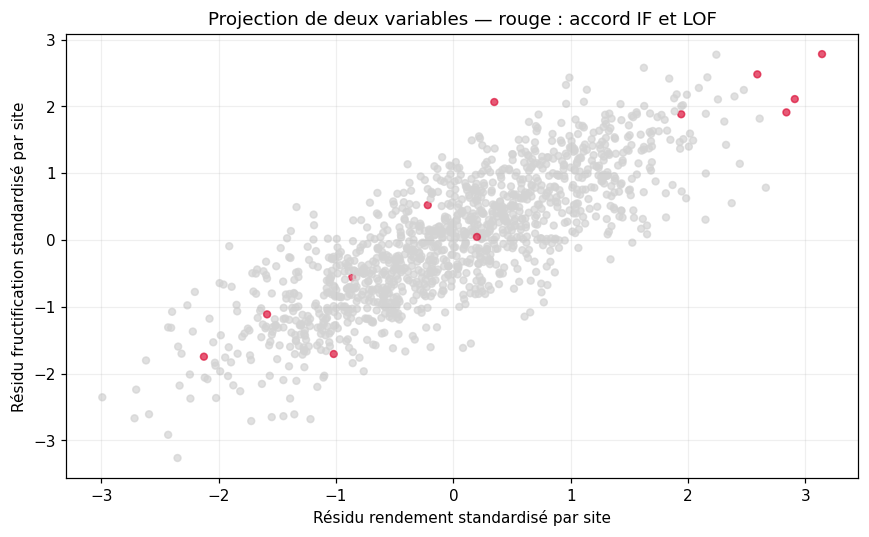

In [38]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=np.where(df.consensus, "crimson", "lightgrey"),
    s=20,
    alpha=0.7,
)
ax.set_xlabel("Résidu rendement standardisé par site")
ax.set_ylabel("Résidu fructification standardisé par site")
ax.set_title("Projection de deux variables — rouge : accord IF et LOF")
fig.tight_layout()
plt.show()


### Comparer les paramètres et les corrélations


In [39]:
sensitivity = []
for contamination in [0.01, 0.02, 0.05]:
    if_cut = np.quantile(df.IF_score, 1 - contamination)
    for k in [10, 20, 35]:
        model = LocalOutlierFactor(n_neighbors=k, contamination=contamination)
        flags = model.fit_predict(Xs) == -1
        sensitivity.append(
            {
                "contamination": contamination,
                "voisins_LOF": k,
                "IF": int(df.IF_score.gt(if_cut).sum()),
                "LOF": int(flags.sum()),
                "accord": int((df.IF_score.gt(if_cut) & flags).sum()),
            }
        )


,contamination,voisins_LOF,IF,LOF,accord
0,0.01,10,13,13,5
1,0.01,20,13,13,5
2,0.01,35,13,13,7
3,0.02,10,25,25,11
4,0.02,20,25,25,12
5,0.02,35,25,25,14
6,0.05,10,63,63,27
7,0.05,20,63,63,30
8,0.05,35,63,63,34


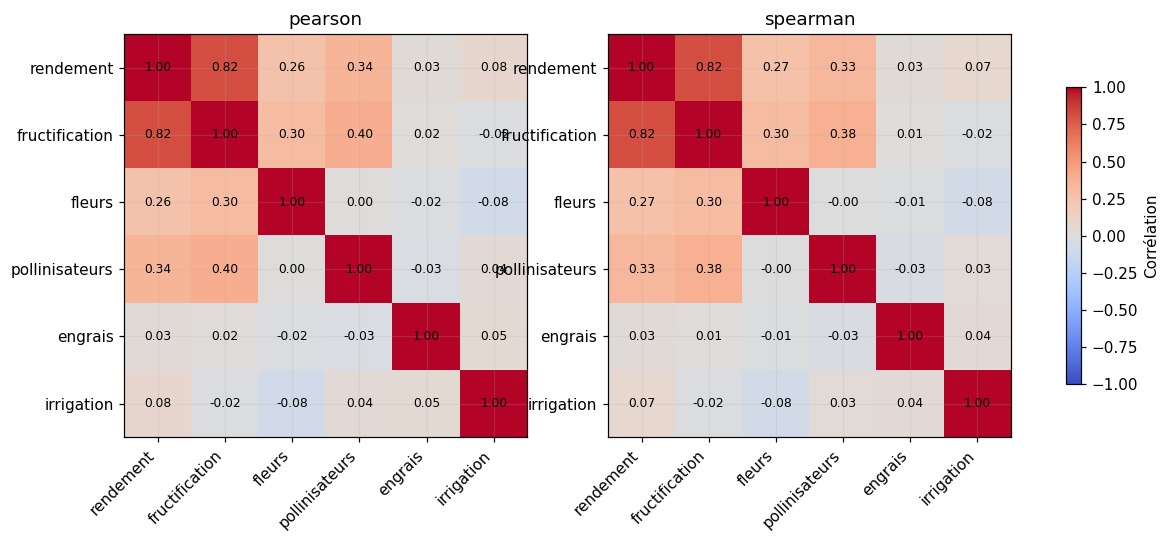

In [40]:
display(pd.DataFrame(sensitivity))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
short = [
    "rendement",
    "fructification",
    "fleurs",
    "pollinisateurs",
    "engrais",
    "irrigation",
]
for ax, method in zip(axes, ["pearson", "spearman"]):
    mat = X.corr(method=method)
    im = ax.imshow(mat, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(short)), short, rotation=45, ha="right")
    ax.set_yticks(range(len(short)), short)
    ax.set_title(method)
    for i in range(len(short)):
        for j in range(len(short)):
            ax.text(j, i, f"{mat.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=list(axes), shrink=0.7, label="Corrélation")
plt.show()


In [41]:
display(
    Markdown(
        "**Lecture :** si les listes changent avec le voisinage ou le quota, les profils sont sensibles au paramétrage. Ces scores servent à prioriser une lecture des séries, pas à supprimer des relevés."
    )
)


**Lecture :** si les listes changent avec le voisinage ou le quota, les profils sont sensibles au paramétrage. Ces scores servent à prioriser une lecture des séries, pas à supprimer des relevés.

### Préparer les détections


In [42]:
ml = []


In [43]:
for name, cut in [("IF", -iso.offset_), ("LOF", -lof.offset_)]:
    ml.append(
        pd.DataFrame(
            {
                "observation": df.orchard_survey_id,
                "groupe": df.site_code,
                "variable": "résidus : " + ", ".join(features),
                "methode": name,
                "valeur": df[name + "_score"],
                "score": df[name + "_score"],
                "borne_basse": -np.inf,
                "borne_haute": cut,
                "n_reference": len(df),
                "applicable": True,
                "signalee": df[name + "_flag"],
                "regle": f"score > {cut:.6g} ; contamination=0.02",
                "interpretation": "Combinaison rare de mesures corrigées du site et de la saison ; vérifier série et notes.",
            }
        )
    )


In [44]:
all_tests = pd.concat([tests, *ml], ignore_index=True)
meta = df[
    [
        "orchard_survey_id",
        "site_code",
        "survey_period",
        "yield_kg_ha",
        "fruit_set_rate_pct",
        "yield_yoy_pct",
        "fruit_yoy_pp",
        "agricultural_disturbance_note",
    ]
]


### c. Tableau des anomalies


#### Tableau des anomalies


In [45]:
def bilan(tests, nom, domaine):
    """Affiche les détections et seuils dans le notebook, sans créer de fichiers."""
    tests = tests.copy()
    tests["echelle_seuil"] = np.where(
        tests.methode.isin(
            ["Binomial_conditionnel_BH", "Fisher_exact_BH", "IF", "LOF", "LOF_k5"]
        ),
        "score",
        "valeur",
    )
    flagged = tests.loc[tests.signalee].copy()
    cols = [
        "groupe", "variable", "methode", "borne_basse", "borne_haute",
        "n_reference", "regle", "echelle_seuil",
    ]
    seuils = tests[cols].drop_duplicates().reset_index(drop=True)
    assert flagged.observation.notna().all()
    print(
        f"{len(flagged)} détections ; {flagged.observation.nunique()} identifiants distincts "
        "(plusieurs méthodes peuvent signaler la même observation)."
    )
    print("Anomalies détectées (tableau complet) :")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(flagged.reset_index(drop=True))
    print(f"Seuils utilisés : {len(seuils)} combinaisons (premières 20 lignes) :")
    display(seuils.head(20))
    return flagged


In [46]:
all_tests = all_tests.merge(
    meta,
    left_on="observation",
    right_on="orchard_survey_id",
    how="left",
    validate="many_to_one",
)
all_tests["interpretation"] = (
    all_tests.interpretation
    + " Note renseignée : "
    + all_tests.agricultural_disturbance_note.fillna(
        "[aucune note renseignée, cause inconnue]"
    )
)
register = bilan(all_tests, "orchard_surveys", "ecology")


106 détections ; 64 identifiants distincts (plusieurs méthodes peuvent signaler la même observation).
Anomalies détectées (tableau complet) :
Seuils utilisés : 224 combinaisons (premières 20 lignes) :


,observation,groupe,variable,methode,valeur,score,borne_basse,borne_haute,n_reference,...,orchard_survey_id,site_code,survey_period,yield_kg_ha,fruit_set_rate_pct,yield_yoy_pct,fruit_yoy_pp,agricultural_disturbance_note,echelle_seuil
0,ORC-0000526,site_code=AVL-ECJ,yield_kg_ha_resid,IQR,438.926108,438.926108,-408.372024,414.311884,78,...,ORC-0000526,AVL-ECJ,2023-10-01,1474.579639,65.9,42.178901,14.8,NaN,valeur
1,ORC-0000532,site_code=AVL-ECJ,yield_kg_ha_resid,IQR,485.854680,485.854680,-408.372024,414.311884,78,...,ORC-0000532,AVL-ECJ,2024-04-01,1553.546798,76.5,18.179990,9.4,NaN,valeur
2,ORC-0000532,site_code=AVL-ECJ,yield_kg_ha_resid,Z-score,485.854680,3.141657,-463.922693,463.948166,78,...,ORC-0000532,AVL-ECJ,2024-04-01,1553.546798,76.5,18.179990,9.4,NaN,valeur
3,ORC-0000498,site_code=AVL-ECJ,yield_kg_ha_delta_resid,IQR,563.687192,563.687192,-545.155583,547.307471,77,...,ORC-0000498,AVL-ECJ,2021-06-01,1399.499179,71.8,25.153451,14.1,NaN,valeur
4,ORC-0000526,site_code=AVL-ECJ,yield_kg_ha_delta_resid,IQR,662.921182,662.921182,-545.155583,547.307471,77,...,ORC-0000526,AVL-ECJ,2023-10-01,1474.579639,65.9,42.178901,14.8,NaN,valeur
5,ORC-0000533,site_code=AVL-ECJ,yield_kg_ha_delta_resid,IQR,-561.379310,-561.379310,-545.155583,547.307471,77,...,ORC-0000533,AVL-ECJ,2024-05-01,1206.093596,57.9,-12.761459,-7.1,NaN,valeur
6,ORC-0000526,site_code=AVL-ECJ,yield_kg_ha_delta_resid,Z-score,662.921182,3.017797,-660.880001,659.006139,77,...,ORC-0000526,AVL-ECJ,2023-10-01,1474.579639,65.9,42.178901,14.8,NaN,valeur
7,ORC-0000498,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,IQR,27.200000,27.200000,-26.700000,26.100000,77,...,ORC-0000498,AVL-ECJ,2021-06-01,1399.499179,71.8,25.153451,14.1,NaN,valeur
8,ORC-0000533,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,IQR,-30.300000,-30.300000,-26.700000,26.100000,77,...,ORC-0000533,AVL-ECJ,2024-05-01,1206.093596,57.9,-12.761459,-7.1,NaN,valeur
9,ORC-0000947,site_code=AVL-FNQ,yield_kg_ha_resid,IQR,-378.994764,-378.994764,-378.603894,393.551865,78,...,ORC-0000947,AVL-FNQ,2019-11-01,567.500000,34.5,NaN,NaN,storm-related flower loss,valeur


,groupe,variable,methode,borne_basse,borne_haute,n_reference,regle,echelle_seuil
0,site_code=AVL-ECJ,yield_kg_ha_resid,IQR,-408.372024,414.311884,78,hors Q1−1.5×IQR ; Q3+1.5×IQR,valeur
1,site_code=AVL-ECJ,yield_kg_ha_resid,Z-score,-463.922693,463.948166,78,|z| > 3,valeur
2,site_code=AVL-ECJ,yield_kg_ha_resid,Z-modifie,-555.310152,547.699314,78,|z_mod| > 3.5,valeur
3,site_code=AVL-ECJ,fruit_set_rate_pct_resid,IQR,-21.700000,22.100000,78,hors Q1−1.5×IQR ; Q3+1.5×IQR,valeur
4,site_code=AVL-ECJ,fruit_set_rate_pct_resid,Z-score,-23.171145,23.596786,78,|z| > 3,valeur
5,site_code=AVL-ECJ,fruit_set_rate_pct_resid,Z-modifie,-29.274110,28.324110,78,|z_mod| > 3.5,valeur
6,site_code=AVL-ECJ,yield_kg_ha_delta_resid,IQR,-545.155583,547.307471,77,hors Q1−1.5×IQR ; Q3+1.5×IQR,valeur
7,site_code=AVL-ECJ,yield_kg_ha_delta_resid,Z-score,-660.880001,659.006139,77,|z| > 3,valeur
8,site_code=AVL-ECJ,yield_kg_ha_delta_resid,Z-modifie,-745.138241,726.143168,77,|z_mod| > 3.5,valeur
9,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,IQR,-26.700000,26.100000,77,hors Q1−1.5×IQR ; Q3+1.5×IQR,valeur


In [47]:
worst = df.nsmallest(1, "yield_yoy_pct").iloc[0]
summary = {
    "n": len(df),
    "stats": int(df.stat_flag.sum()),
    "IF": int(df.IF_flag.sum()),
    "LOF": int(df.LOF_flag.sum()),
    "consensus": int(df.consensus.sum()),
    "max_yoy_drop_id": worst.orchard_survey_id,
    "max_yoy_drop_pct": float(worst.yield_yoy_pct),
    "max_yoy_drop_site": worst.site_code,
}


In [48]:
display(
    Markdown(
        f"**Bilan calculé :** {summary['stats']} relevés signalés par les tests contextuels ; "
        f"IF {summary['IF']}, LOF {summary['LOF']}, accord {summary['consensus']}. "
        f"La baisse annuelle relative la plus forte est {worst.yield_yoy_pct:.1f} % "
        f"pour {worst.orchard_survey_id} ({worst.site_code}, {worst.survey_period:%Y-%m}). "
        "Une baisse annuelle ne prouve ni erreur ni cause environnementale : les séries et les notes doivent être relues."
    )
)


**Bilan calculé :** 35 relevés signalés par les tests contextuels ; IF 25, LOF 25, accord 12. La baisse annuelle relative la plus forte est -54.5 % pour ORC-0000812 (AVL-HUA, 2021-08). Une baisse annuelle ne prouve ni erreur ni cause environnementale : les séries et les notes doivent être relues.

### Vérifier les identifiants


In [49]:
assert df.orchard_survey_id.is_unique
assert len(df) == len(raw.drop_duplicates())


### Rapprocher vergers et chauves-souris


In [50]:
bat_path = ROOT / "data/ecology/cleaned/bat_surveys_cleaned.csv"
bat = pd.read_csv(
    bat_path,
    usecols=["site_code", "survey_start", "observed_bat_count", "observation_hours"],
)
bat["survey_start"] = pd.to_datetime(bat.survey_start, errors="raise")
for col in ["observed_bat_count", "observation_hours"]:
    bat[col] = pd.to_numeric(bat[col], errors="coerce")
bat["month"] = bat.survey_start.dt.to_period("M")


In [51]:
bat_month = (
    bat.groupby(["site_code", "month"])
    .agg(
        observations=("survey_start", "size"),
        bat_count=("observed_bat_count", "sum"),
        hours=("observation_hours", "sum"),
    )
    .reset_index()
)
bat_month["bats_per_hour"] = bat_month.bat_count / bat_month.hours.replace(0, np.nan)


In [52]:
orchard_month = df[
    [
        "orchard_survey_id",
        "site_code",
        "survey_period",
        "yield_kg_ha_resid",
        "fruit_set_rate_pct_resid",
        "stat_flag",
    ]
].copy()
orchard_month["month"] = orchard_month.survey_period.dt.to_period("M")
assert not orchard_month.duplicated(["site_code", "month"]).any()


In [53]:
linked = orchard_month.merge(
    bat_month,
    on=["site_code", "month"],
    how="left",
    validate="one_to_one",
    indicator=True,
)
print(
    "Relevés verger :",
    len(linked),
    "| avec chauves-souris même site/mois :",
    int(linked._merge.eq("both").sum()),
)
print("Sites communs :", linked.loc[linked._merge.eq("both"), "site_code"].nunique())
assert len(linked) == len(df)


Relevés verger : 1248 | avec chauves-souris même site/mois : 1248
Sites communs : 16


### Corriger la saisonnalité des deux sources


In [54]:
linked["cal_month"] = linked["month"].dt.month
linked["bats_resid"] = np.nan
for _, site_month_data in linked.groupby(["site_code", "cal_month"]):
    for index in site_month_data.index:
        other_years_bat_rates = site_month_data.loc[site_month_data.index != index, "bats_per_hour"].dropna()
        if len(other_years_bat_rates) >= 4:
            linked.at[index, "bats_resid"] = (
                linked.at[index, "bats_per_hour"] - other_years_bat_rates.median()
            )
paired = linked[
    ["site_code", "yield_kg_ha_resid", "fruit_set_rate_pct_resid", "bats_resid"]
].dropna()
random_generator = np.random.default_rng(42)
site_ids = paired.site_code.unique()


In [55]:
for col, label in [
    ("yield_kg_ha_resid", "rendement"),
    ("fruit_set_rate_pct_resid", "fructification"),
]:
    if (
        len(paired) >= 10
        and paired[col].nunique() > 1
        and paired.bats_resid.nunique() > 1
    ):
        rho = float(spearmanr(paired[col], paired.bats_resid).statistic)
        estimates = []
        for _ in range(400):
            chosen = random_generator.choice(site_ids, size=len(site_ids), replace=True)
            sample = pd.concat(
                [paired.loc[paired.site_code.eq(site)] for site in chosen],
                ignore_index=True,
            )
            if sample[col].nunique() > 1 and sample.bats_resid.nunique() > 1:
                estimates.append(
                    float(spearmanr(sample[col], sample.bats_resid).statistic)
                )
        low, high = np.quantile(estimates, [0.025, 0.975])
        print(
            f"Spearman (résidu {label} / résidu chauves-souris par heure) : rho={rho:.3f} ; intervalle bootstrap par site [{low:.3f}, {high:.3f}] ; {len(paired)} relevés, {len(site_ids)} sites"
        )
    else:
        print(
            label, ": effectif ou variance insuffisants pour calculer une corrélation"
        )


Spearman (résidu rendement / résidu chauves-souris par heure) : rho=0.146 ; intervalle bootstrap par site [0.093, 0.199] ; 1248 relevés, 16 sites
Spearman (résidu fructification / résidu chauves-souris par heure) : rho=0.195 ; intervalle bootstrap par site [0.130, 0.254] ; 1248 relevés, 16 sites


### Corrélations observées


In [56]:
print(
    "Lecture exploratoire : mesures répétées, autocorrélation et facteurs non observés ; aucune conclusion causale ou p-valeur naïve."
)


Lecture exploratoire : mesures répétées, autocorrélation et facteurs non observés ; aucune conclusion causale ou p-valeur naïve.


In [57]:
display(
    linked.loc[
        linked.stat_flag & linked._merge.eq("both"),
        [
            "orchard_survey_id",
            "site_code",
            "month",
            "yield_kg_ha_resid",
            "fruit_set_rate_pct_resid",
            "bats_per_hour",
        ],
    ].head(12)
)


,orchard_survey_id,site_code,month,yield_kg_ha_resid,fruit_set_rate_pct_resid,bats_per_hour
29,ORC-0000498,AVL-ECJ,2021-06,217.101806,8.9,0.672515
57,ORC-0000526,AVL-ECJ,2023-10,438.926108,15.1,0.582192
63,ORC-0000532,AVL-ECJ,2024-04,485.854680,21.9,0.630435
64,ORC-0000533,AVL-ECJ,2024-05,-75.524631,-8.4,0.501672
86,ORC-0000945,AVL-FNQ,2019-09,-196.552356,-18.0,0.074349
88,ORC-0000947,AVL-FNQ,2019-11,-378.994764,-10.8,0.168776
133,ORC-0000992,AVL-FNQ,2023-08,-249.984293,-17.8,0.258621
214,ORC-0000449,AVL-GRB,2023-11,-344.950368,-22.0,0.192308
244,ORC-0000791,AVL-HUA,2019-11,337.085954,11.8,0.237288
252,ORC-0000799,AVL-HUA,2020-07,-224.735849,-17.0,0.461538


### Autocorrélation des relevés


In [58]:
autocorrelations = []
for site_code, site_data in df.groupby("site_code"):
    site_data = site_data.sort_values("survey_period")
    for lag_months in [1, 12]:
        autocorrelations.append(
            {
                "site_code": site_code,
                "decalage_mois": lag_months,
                "rendement_brut": site_data["yield_kg_ha"].autocorr(lag=lag_months),
                "rendement_corrige": site_data["yield_kg_ha_resid"].autocorr(
                    lag=lag_months
                ),
            }
        )
autocorrelation_table = pd.DataFrame(autocorrelations)


,rendement_brut,rendement_corrige
decalage_mois,,
1,0.238,-0.015
12,0.384,-0.128


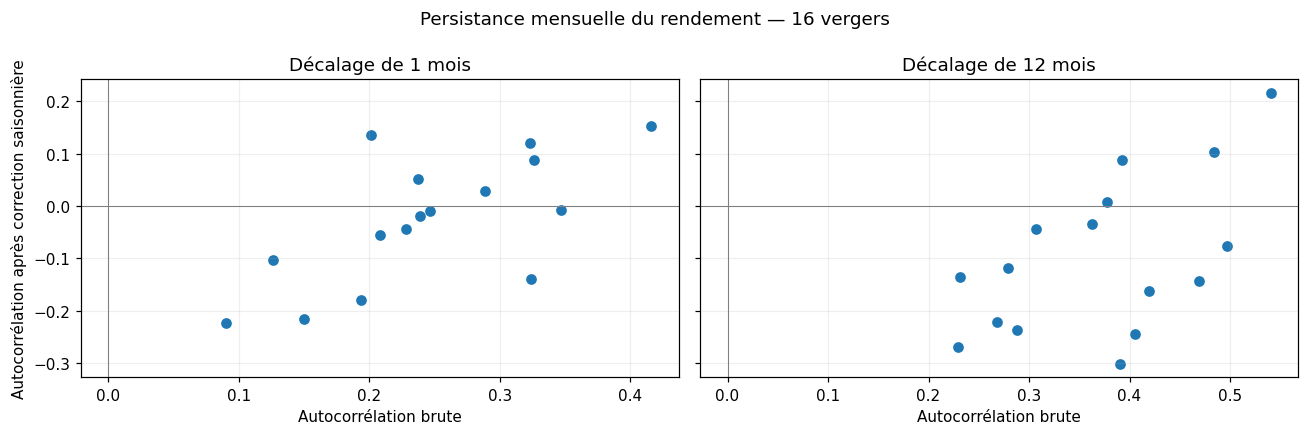

In [59]:
summary_lags = autocorrelation_table.groupby("decalage_mois")[
    ["rendement_brut", "rendement_corrige"]
].median()
display(summary_lags.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, lag_months in zip(axes, [1, 12]):
    selected_sites = autocorrelation_table.loc[
        autocorrelation_table["decalage_mois"] == lag_months
    ]
    ax.scatter(
        selected_sites["rendement_brut"],
        selected_sites["rendement_corrige"],
        s=36,
    )
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)
    ax.set(title=f"Décalage de {lag_months} mois", xlabel="Autocorrélation brute")
axes[0].set_ylabel("Autocorrélation après correction saisonnière")
plt.suptitle("Persistance mensuelle du rendement — 16 vergers")
plt.tight_layout()
plt.show()


In [60]:
print(
    "Lecture : vérifier les autocorrélations avant d'interpréter des variations "
    "mensuelles ; les séries répétées ne constituent pas des observations indépendantes."
)


Lecture : vérifier les autocorrélations avant d'interpréter des variations mensuelles ; les séries répétées ne constituent pas des observations indépendantes.


### Décomposition STL du rendement d’un verger

On utilise `statsmodels` pour distinguer la tendance, la saisonnalité et les variations qui restent.


In [61]:
rendements_moyens = df.groupby("site_code")["yield_kg_ha"].mean()
site_stl = (rendements_moyens - rendements_moyens.median()).abs().idxmin()
serie_stl = df.loc[df.site_code.eq(site_stl)].set_index("survey_period")["yield_kg_ha"]
serie_stl = serie_stl.asfreq("MS")
assert len(serie_stl) == 78 and serie_stl.notna().all()
resultat_stl = STL(serie_stl, period=12, robust=True).fit()
print("Verger choisi :", site_stl, "|", len(serie_stl), "mois")


Verger choisi : AVL-ECJ | 78 mois


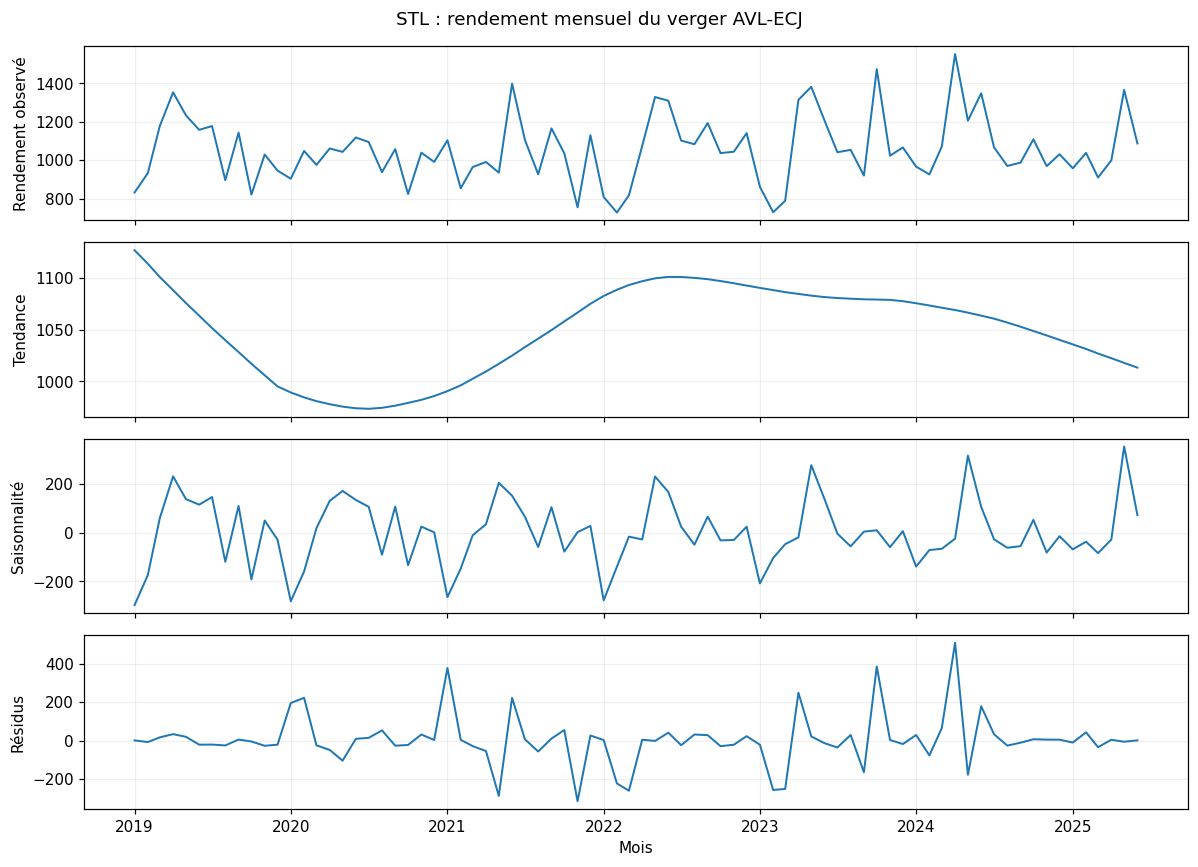

In [62]:
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, valeurs, titre in zip(axes,
        [serie_stl, resultat_stl.trend, resultat_stl.seasonal, resultat_stl.resid],
        ["Rendement observé", "Tendance", "Saisonnalité", "Résidus"]):
    ax.plot(serie_stl.index, valeurs, linewidth=1.3)
    ax.set_ylabel(titre)
axes[-1].set_xlabel("Mois")
fig.suptitle("STL : rendement mensuel du verger " + site_stl)
plt.tight_layout(); plt.show()


In [63]:
residus_stl = pd.DataFrame({"rendement": serie_stl,
                            "residu_stl": resultat_stl.resid})
residus_stl["amplitude"] = residus_stl.residu_stl.abs()
display(residus_stl.nlargest(5, "amplitude")
        [["rendement", "residu_stl"]].round(2))


,rendement,residu_stl
survey_period,,
2024-04-01,1553.55,508.56
2023-10-01,1474.58,385.13
2021-01-01,1103.68,377.37
2021-11-01,754.36,-314.90
2021-05-01,935.03,-287.16


**Lecture :** la STL sépare le rendement en tendance, saisonnalité annuelle (12 mois) et résidus. Les mois aux résidus les plus forts sont à examiner, pas forcément des erreurs. Ce résultat concerne **un seul verger** et complète les comparaisons saisonnières déjà faites pour les 16 sites.


### d. Comparer les méthodes de détection


In [64]:
display(pd.crosstab(df.stat_flag,df.IF_flag,rownames=['Univariée'],
                   colnames=['Isolation Forest']))
display(pd.crosstab(df.IF_flag,df.LOF_flag,rownames=['Isolation Forest'],
                   colnames=['LOF']))

Isolation Forest,False,True
Univariée,,
False,1197,16
True,26,9


LOF,False,True
Isolation Forest,,
False,1210,13
True,13,12


# 5. Règles d’association (Apriori)


### a. Construire des paniers catégoriels


In [65]:
paniers_orchard=[]
for r in df.itertuples():
    paniers_orchard.append({
        'saison='+str((r.survey_period.month-1)//3+1),
        'perturbation='+('oui' if pd.notna(r.agricultural_disturbance_note) else 'non'),
        'rendement='+('bas' if r.yield_kg_ha_resid<0 else 'haut'),
        'fructification='+('basse' if r.fruit_set_rate_pct_resid<0 else 'haute'),
        'pollinisateurs='+('hauts' if r.other_pollinator_activity>=df.other_pollinator_activity.median() else 'bas')})
print('Paniers :',len(paniers_orchard))

Paniers : 1248


### b. Rechercher les ensembles fréquents


In [66]:
def apriori_itemsets(transactions, min_support=.08, max_size=3):
    """Apriori : construire et élaguer des ensembles fréquents de taille 1 à 3."""
    paniers=[set(t) for t in transactions]
    n=len(paniers)
    counts=Counter(item for panier in paniers for item in panier)
    freq={frozenset([x]):v/n for x,v in counts.items() if v/n>=min_support}
    all_freq=dict(freq)
    for k in range(2,max_size+1):
        uniques=sorted(set().union(*[set(f) for f in freq])) if freq else []
        candidates=(frozenset(combo) for combo in combinations(uniques,k))
        candidates=[c for c in candidates if all(frozenset(s) in freq
                        for s in combinations(c,k-1))]
        freq={c:sum(c<=panier for panier in paniers)/n for c in candidates}
        freq={c:s for c,s in freq.items() if s>=min_support}
        all_freq.update(freq)
    return all_freq

In [67]:
freq_orchard=apriori_itemsets(paniers_orchard, min_support=0.1, max_size=3)
print('Ensembles fréquents :',len(freq_orchard))

Ensembles fréquents : 97


### c. Règles : support, confiance, lift


In [68]:
def regles_apriori(freq, min_confiance=.6, min_lift=1.1):
    """Extraire support, confiance et lift pour toutes les règles fréquentes."""
    lignes=[]
    for ensemble,support in freq.items():
        if len(ensemble)<2:continue
        for taille in range(1,len(ensemble)):
            for part in combinations(sorted(ensemble),taille):
                gauche=frozenset(part);droite=ensemble-gauche
                confiance=support/freq[gauche]
                lift=confiance/freq[droite]
                if confiance>=min_confiance and lift>=min_lift:
                    lignes.append({'antecedent':' + '.join(sorted(gauche)),
                        'consequent':' + '.join(sorted(droite)),
                        'support':support,'confiance':confiance,'lift':lift})
    return pd.DataFrame(lignes,columns=['antecedent','consequent',
                                        'support','confiance','lift'])

In [69]:
regles_orchard=regles_apriori(freq_orchard)
print('Règles retenues :',len(regles_orchard))
display(regles_orchard.sort_values('lift',ascending=False).head(12).round(3))

Règles retenues : 40


,antecedent,consequent,support,confiance,lift
16,pollinisateurs=bas + rendement=bas,fructification=basse,0.254,0.883,1.789
35,pollinisateurs=hauts + rendement=haut,fructification=haute,0.253,0.885,1.748
14,fructification=basse + pollinisateurs=bas,rendement=bas,0.254,0.839,1.669
31,fructification=haute + pollinisateurs=bas,rendement=haut,0.163,0.829,1.665
2,fructification=basse,rendement=bas,0.412,0.834,1.661
3,rendement=bas,fructification=basse,0.412,0.820,1.661
11,rendement=bas,fructification=basse + perturbation=non,0.402,0.801,1.660
12,fructification=basse + perturbation=non,rendement=bas,0.402,0.834,1.660
10,fructification=basse,perturbation=non + rendement=bas,0.402,0.815,1.656
13,perturbation=non + rendement=bas,fructification=basse,0.402,0.818,1.656


→ Résultat exploratoire : une association fréquente ne prouve pas une cause.


### d. Anomalies et notes de perturbation


In [70]:
croisement_verger=df[['orchard_survey_id','site_code','survey_period',
    'agricultural_disturbance_note','stat_flag','IF_flag','LOF_flag']].copy()
croisement_verger['note_presente']=croisement_verger.agricultural_disturbance_note.notna()
croisement_verger['anomalie']=croisement_verger[['stat_flag','IF_flag','LOF_flag']].any(axis=1)
display(pd.crosstab(croisement_verger.anomalie,croisement_verger.note_presente))
display(croisement_verger.loc[croisement_verger.anomalie &
    croisement_verger.note_presente].head(20))

note_presente,False,True
anomalie,,
False,1164,20
True,61,3


,orchard_survey_id,site_code,survey_period,agricultural_disturbance_note,stat_flag,IF_flag,LOF_flag,note_presente,anomalie
86,ORC-0000945,AVL-FNQ,2019-09-01,elevated pesticide application,True,False,False,True,True
88,ORC-0000947,AVL-FNQ,2019-11-01,storm-related flower loss,True,False,False,True,True
106,ORC-0000965,AVL-FNQ,2021-05-01,elevated pesticide application,False,True,False,True,True


→ Une note de perturbation est un contexte possible, pas une causalité démontrée.


# 6. Bilan final


### Ce qu’on a trouvé

On a analysé **1 248 relevés mensuels de 16 vergers**. Les rendements et la fructification changent selon les sites et les saisons, donc on a comparé les relevés à l’historique du même verger et du même mois.

Avec les tests statistiques, Isolation Forest et LOF, on a repéré **64 relevés atypiques**. Trois de ces relevés possèdent également une note de perturbation agricole. Le clustering distingue aussi **deux groupes de 8 vergers**, avec des rendements et des taux de fructification moyens différents.

Les corrélations montrent une relation positive forte entre **rendement et fructification** (Pearson ≈ 0,915), et plus modérée entre rendement et activité des autres pollinisateurs (≈ 0,427). La décomposition STL sur un verger montre également des variations qui restent après retrait de la tendance et de la saisonnalité.

### Ce qu’on en conclut

Ces résultats nous donnent des **pistes à vérifier** avec les notes agricoles, les données environnementales et les observations de chauves-souris. Mais une corrélation ou une valeur atypique ne prouve pas sa cause. On a donc **gardé tous les relevés**, y compris les valeurs extrêmes, pour poursuivre l’analyse avec le groupe.
